# 03 — Cohort Retention Analysis

**Objective:** measure how customer purchasing activity evolves after the
first observed purchase.

**Definitions used here:**
* **Cohort** = calendar month of a customer's first *qualifying* (delivered)
  order. First *observed* purchase — customers may have bought on Olist
  before the dataset starts.
* **Month 0** = the acquisition month (retention = 100% by construction).
* **Retained in month N** = placed >=1 delivered order that month.
* Cohort-months extending past the data window are flagged `is_observed`
  and excluded from headline claims — they are NOT zero-filled.

In [1]:
import sys
from pathlib import Path

# Make the repo's src/ package importable when running from notebooks/.
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import data_loading as dl
from src.config import get_engine
from src.visualization import PALETTE, set_style

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
engine = get_engine()


In [2]:
from src import cohort_analysis as ca

orders = dl.load_orders_enriched(engine)
cohort = ca.build_cohort_table(orders)
sizes = cohort.drop_duplicates("cohort_month")[["cohort_month", "cohort_size"]]
sizes

,cohort_month,cohort_size
0,2016-09-01,1
1,2016-10-01,262
10,2016-12-01,1
12,2017-01-01,717
30,2017-02-01,1628
48,2017-03-01,2503
66,2017-04-01,2256
83,2017-05-01,3451
99,2017-06-01,3037
114,2017-07-01,3752


Small early cohorts (2016) reflect Olist's ramp-up; cohorts from 2017-01 onward are large enough to compare.

## Retention matrix (observed months only)

In [3]:
matrix = ca.retention_matrix(cohort)
matrix.round(2)

months_since_first,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,100.00,NaN,NaN,NaN,NaN,NaN,0.38,NaN,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,0.76,0.76
2016-12,100.00,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,100.00,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02,100.00,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN
2017-03,100.00,0.44,0.36,0.40,0.36,0.16,0.16,0.32,0.32,0.08,0.36,0.12,0.20,0.12,0.16,0.24,0.08,0.12,NaN,NaN
2017-04,100.00,0.62,0.22,0.18,0.27,0.27,0.35,0.31,0.31,0.18,0.27,0.09,0.04,0.04,0.09,0.09,0.13,NaN,NaN,NaN
2017-05,100.00,0.46,0.46,0.29,0.29,0.32,0.41,0.14,0.26,0.26,0.26,0.35,0.23,0.03,0.17,0.20,NaN,NaN,NaN,NaN
2017-06,100.00,0.49,0.40,0.43,0.30,0.40,0.36,0.23,0.13,0.20,0.30,0.36,0.16,0.16,0.23,NaN,NaN,NaN,NaN,NaN


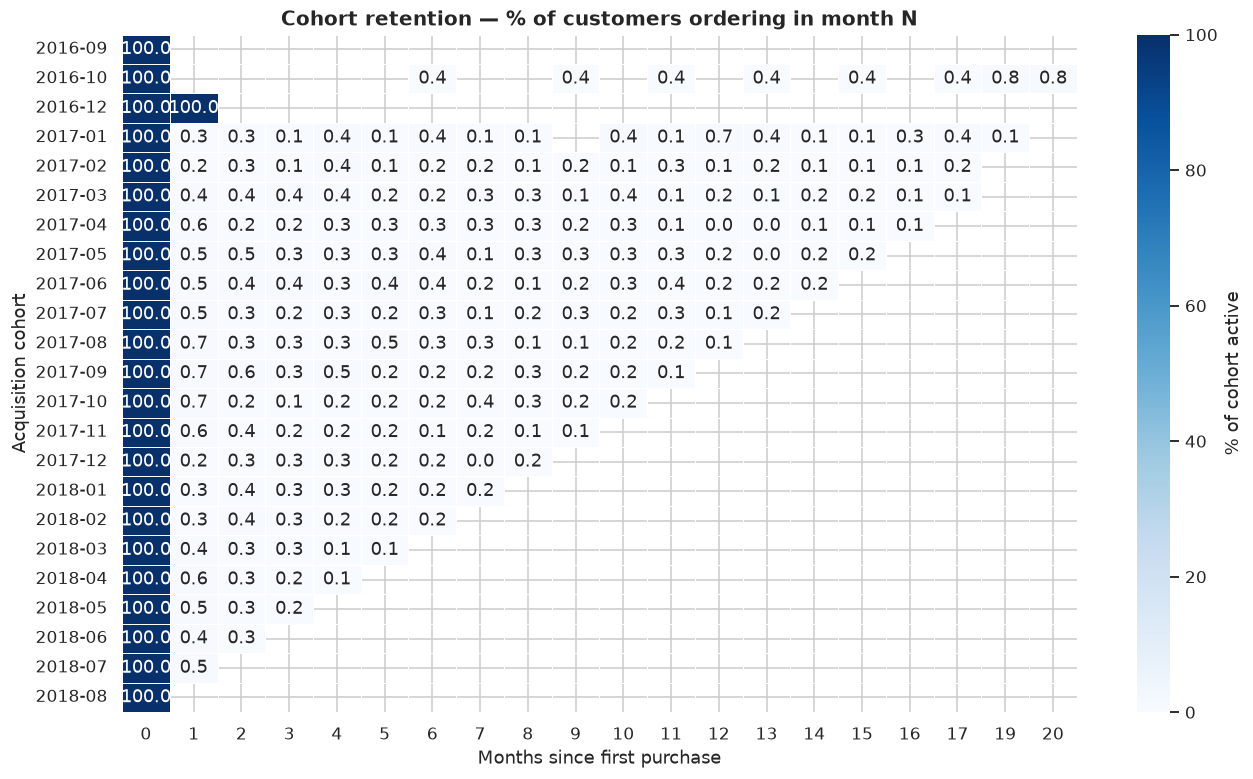

In [4]:
from src.visualization import cohort_heatmap
fig = cohort_heatmap(matrix)
plt.show()

## Average retention per month-since-first

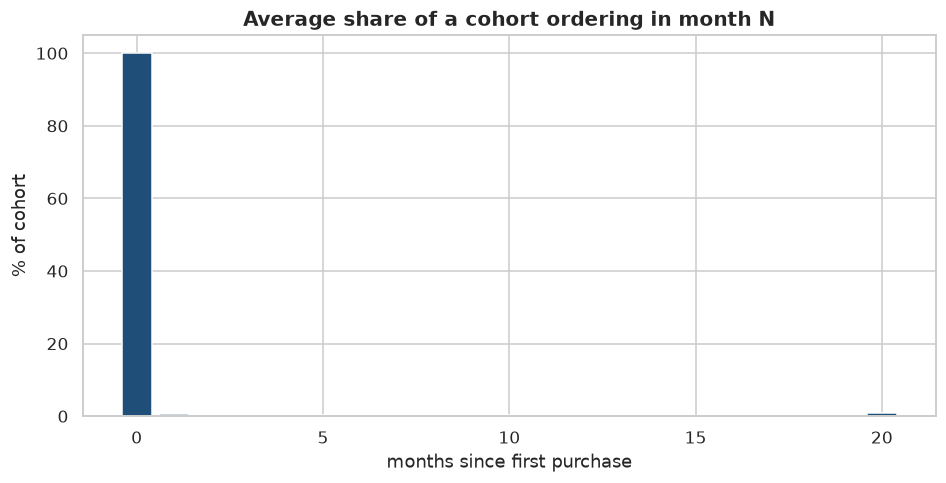

,months_since_first,cohorts_observed,returning_customers,customers_in_window,avg_retention_pct
0,0,23,93358,93358,100.00
1,1,20,421,86951,0.48
2,2,18,273,81001,0.34
3,3,17,192,75123,0.26
4,4,16,176,68617,0.26
5,5,15,140,62035,0.23
6,6,15,129,55523,0.23
7,7,13,102,48973,0.21
8,8,12,86,42131,0.20
9,9,11,60,36338,0.17


In [5]:
summary = ca.cohort_summary(cohort)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(summary["months_since_first"], summary["avg_retention_pct"],
       color=PALETTE["primary"])
ax.set_title("Average share of a cohort ordering in month N")
ax.set_xlabel("months since first purchase")
ax.set_ylabel("% of cohort")
plt.show()
summary.head(13)

## Conclusion

* Month-1 retention is **well under 1%** in every cohort, and it stays
  near zero — there is no meaningful 'return curve' to bend in the
  observed window.
* Longer-horizon numbers (m6, m12) hover at ~0.1-0.5%: repeat behaviour
  exists but is rare and does not strengthen over time.
* **Interpretation:** unlike subscription businesses, Olist shows no
  cohort that 'warms up'. Retention strategy here is not about keeping
  a subscription alive — it is about prompting the second purchase.
* Caveat: 'active in month N' counts a repeat order in *any* later
  month only once per month, so a customer buying in month 3 appears
  at month 3 but not month 2 — the matrix is not cumulative.